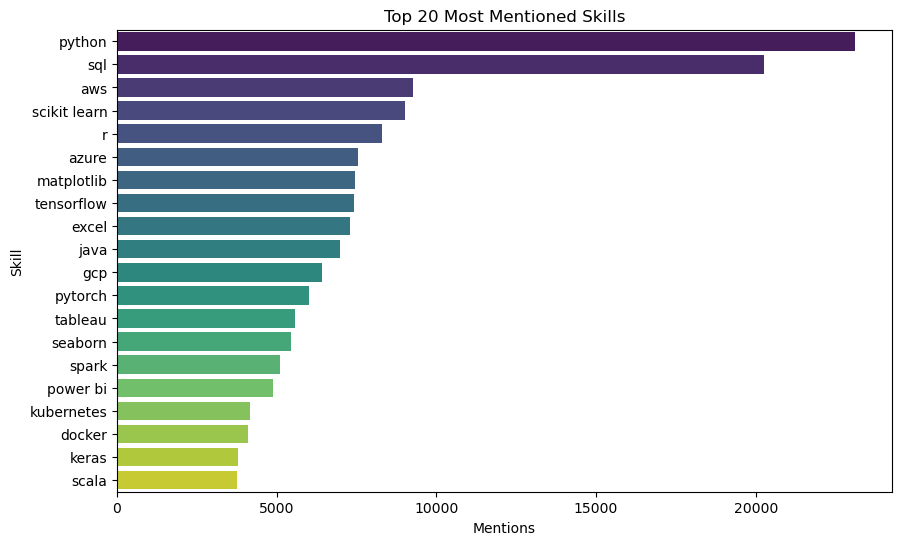

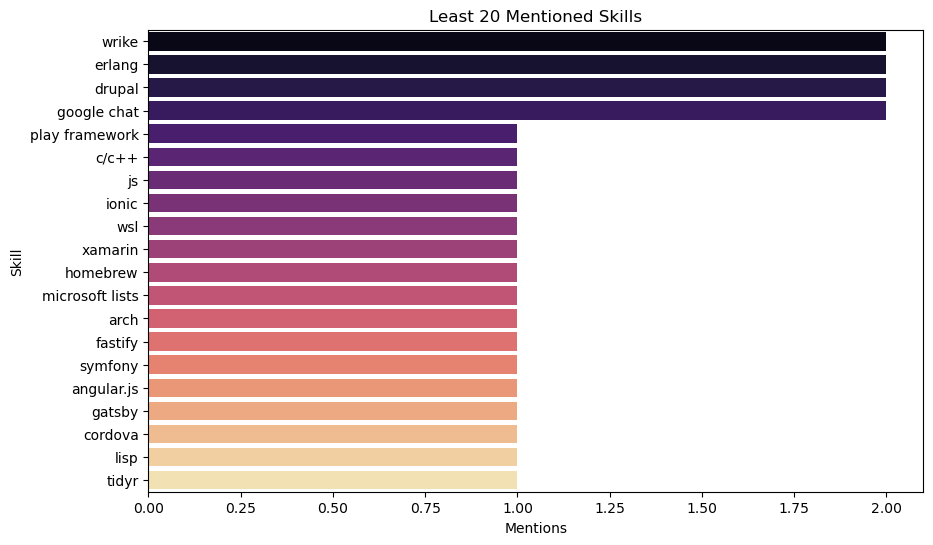

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load skills dataset
skills_df = pd.read_csv("all_skill_matches.csv")

# Sort by mentions
skills_sorted = skills_df.sort_values("mentions", ascending=False)

# Top 20 skills
top_skills = skills_sorted.head(20)

plt.figure(figsize=(10,6))
sns.barplot(data=top_skills, x="mentions", y="skill_clean", hue="skill_clean", dodge=False, palette="viridis", legend=False)
plt.title("Top 20 Most Mentioned Skills")
plt.xlabel("Mentions")
plt.ylabel("Skill")
plt.show()

# Least 20 skills
least_skills = skills_sorted.tail(20)

plt.figure(figsize=(10,6))
sns.barplot(data=least_skills, x="mentions", y="skill_clean", hue="skill_clean", dodge=False, palette="magma",  legend=False)
plt.title("Least 20 Mentioned Skills")
plt.xlabel("Mentions")
plt.ylabel("Skill")
plt.show()

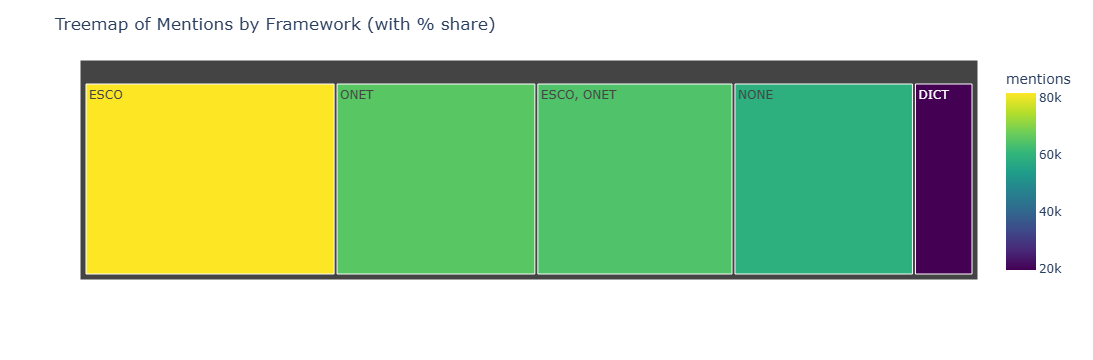

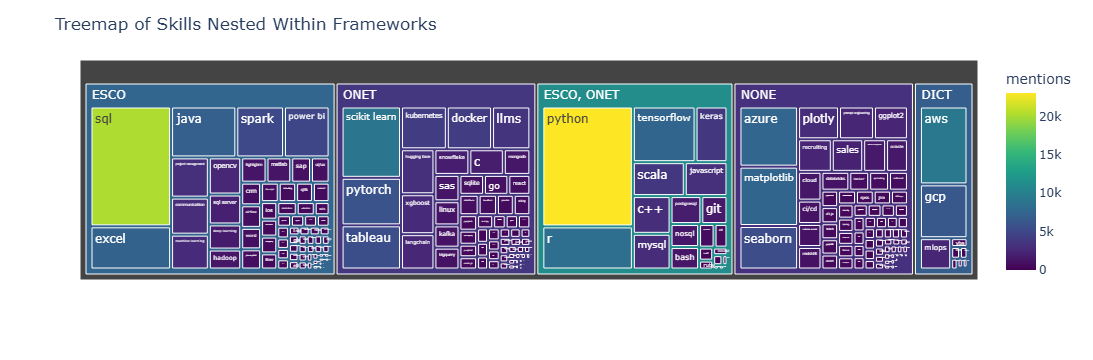

In [2]:
import plotly.express as px
import pandas as pd

#Load dataset
skills_df = pd.read_csv("all_skill_matches.csv")

#Framework totals with percentages
framework_counts = skills_df.groupby("framework")["mentions"].sum().reset_index()
framework_counts["percentage"] = (framework_counts["mentions"] / framework_counts["mentions"].sum() * 100).round(2)

fig1 = px.treemap(framework_counts,
                  path=["framework"],
                  values="mentions",
                  color="mentions",
                  color_continuous_scale="Viridis",
                  hover_data=["mentions", "percentage"])
fig1.update_layout(title="Treemap of Mentions by Framework (with % share)")
fig1.show()

#Nested treemap: frameworks → skills
fig2 = px.treemap(skills_df,
                  path=["framework", "skill_clean"],
                  values="mentions",
                  color="mentions",
                  color_continuous_scale="Viridis",
                  hover_data=["mentions"])
fig2.update_layout(title="Treemap of Skills Nested Within Frameworks")
fig2.show()


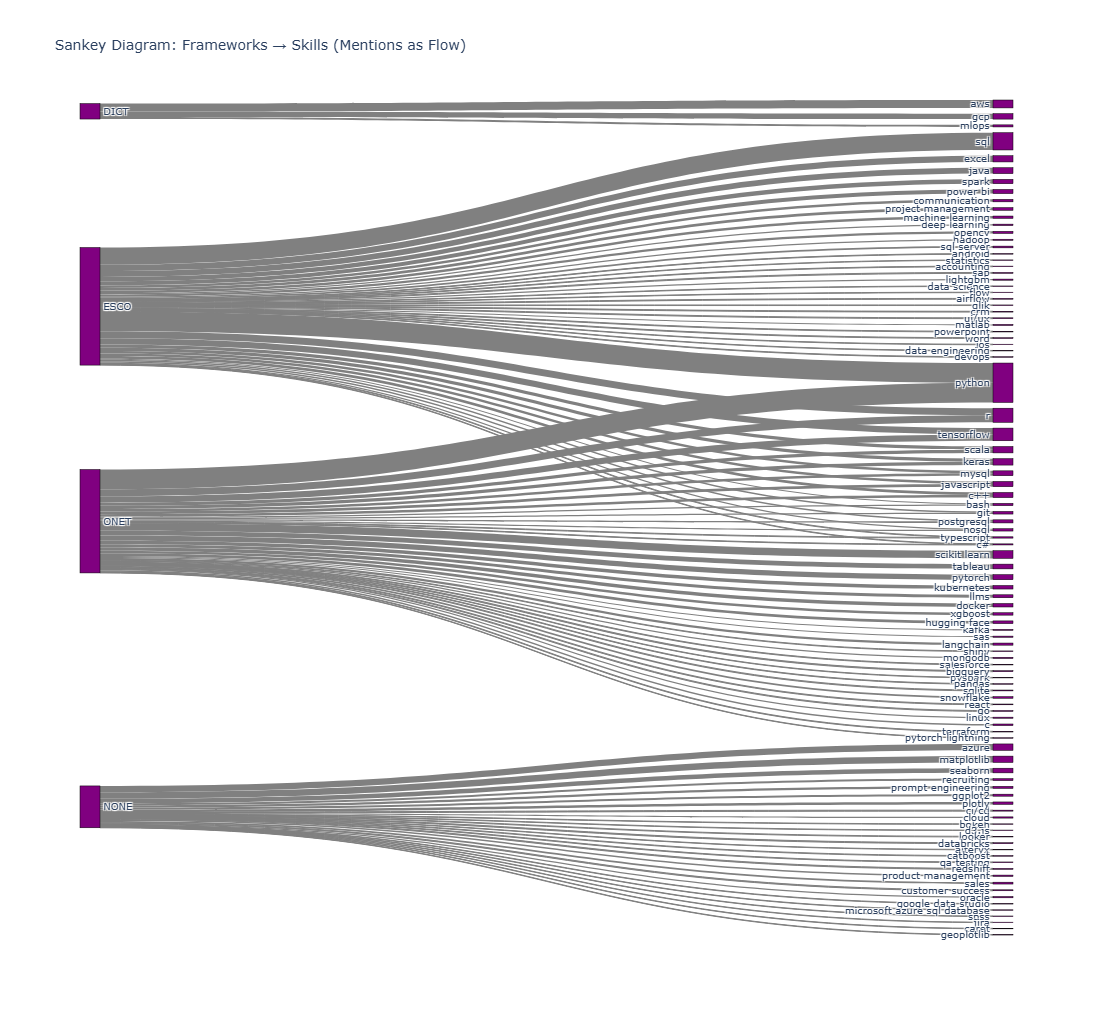

In [8]:
import pandas as pd
import plotly.graph_objects as go

# Load dataset
skills_df = pd.read_csv("all_skill_matches.csv")

# filter to reduce clutter 
filtered_df = skills_df[skills_df["mentions"] > 500]

# Build source-target-value lists
sources = []
targets = []
values = []

# Collect unique labels for frameworks + skills
labels = list(set(filtered_df["framework"].unique().tolist() + filtered_df["skill_clean"].unique().tolist()))

for _, row in filtered_df.iterrows():
    skill = row["skill_clean"]
    mentions = row["mentions"]
    for fw in str(row["framework"]).split(","):
        fw = fw.strip()
        sources.append(labels.index(fw))
        targets.append(labels.index(skill))
        values.append(mentions)

# Create Sankey diagram
fig = go.Figure(go.Sankey(
    node=dict(
        pad=15,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=labels,
        color="purple"
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color="gray"
    )
))

fig.update_layout(title_text="Sankey Diagram: Frameworks → Skills (Mentions as Flow)",
                  font_size=10,
                 width=1100,
                 height=1000)
fig.show()


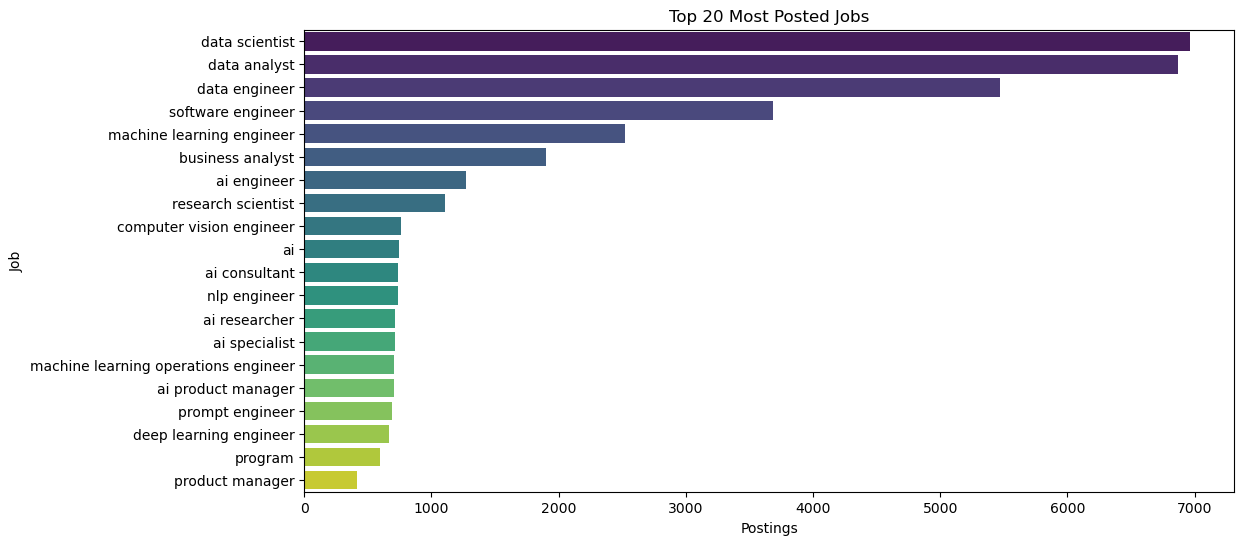

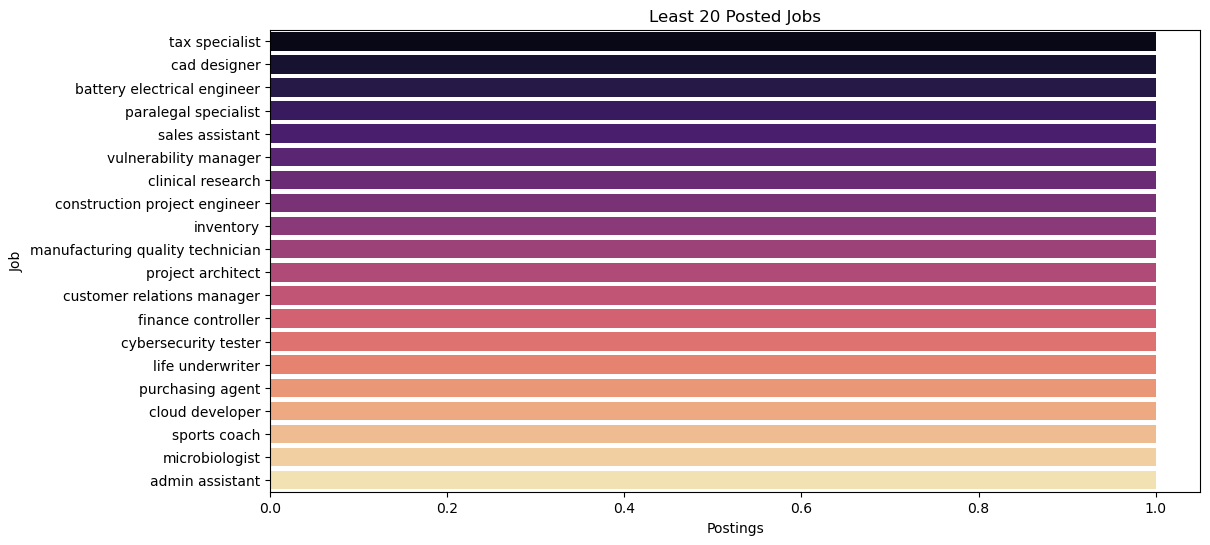

In [4]:
#Jobs visualisation

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

jobs_df = pd.read_csv("C:\\Users\\Lamees\\Documents\\Lamees Group project\\ONET+framework+llm\\job_title_results_filled.csv")
jobs_sorted = jobs_df.sort_values("postings", ascending=False)

# Top 20 jobs
plt.figure(figsize=(12,6))
sns.barplot(data=jobs_sorted.head(20), x="postings", y="title_clean", hue="title_clean",
            palette="viridis", legend=False)
plt.title("Top 20 Most Posted Jobs")
plt.xlabel("Postings")
plt.ylabel("Job")
plt.show()

# Least 20 jobs
plt.figure(figsize=(12,6))
sns.barplot(data=jobs_sorted.tail(20), x="postings", y="title_clean", hue="title_clean",
            palette="magma", legend=False)
plt.title("Least 20 Posted Jobs")
plt.xlabel("Postings")
plt.ylabel("Job")
plt.show()


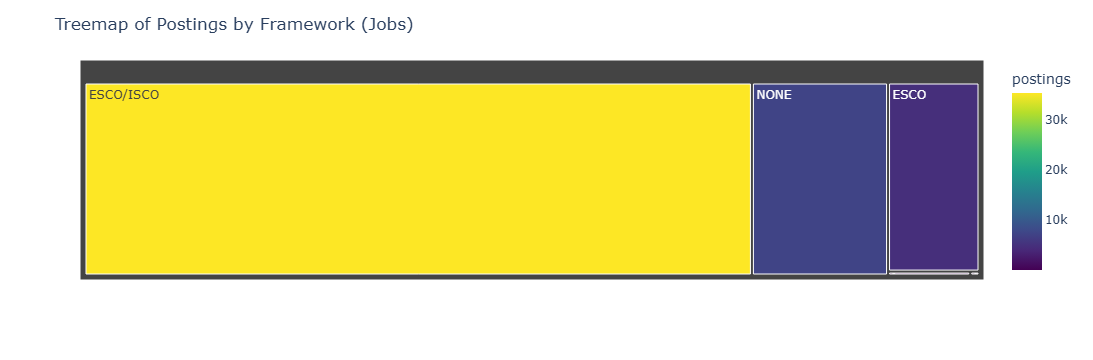

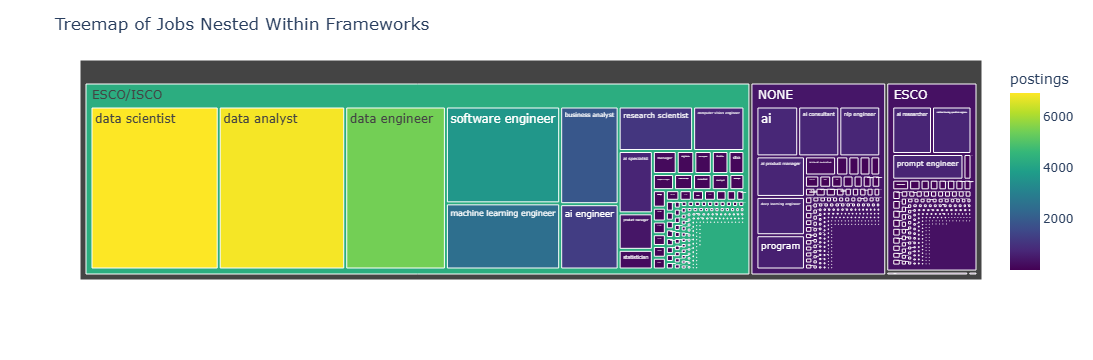

In [5]:
import plotly.express as px

# Aggregate mentions by framework
framework_counts = jobs_df.groupby("framework")["postings"].sum().reset_index()
framework_counts["percentage"] = (framework_counts["postings"] / framework_counts["postings"].sum() * 100).round(2)

# Framework totals
fig = px.treemap(framework_counts,
                 path=["framework"],
                 values="postings",
                 color="postings",
                 color_continuous_scale="Viridis",
                 hover_data=["postings", "percentage"])
fig.update_layout(title="Treemap of Postings by Framework (Jobs)")
fig.show()

# Nested treemap: frameworks to jobs
fig2 = px.treemap(jobs_df,
                  path=["framework", "title_clean"],
                  values="postings",
                  color="postings",
                  color_continuous_scale="Viridis",
                  hover_data=["postings"])
fig2.update_layout(title="Treemap of Jobs Nested Within Frameworks")
fig2.show()


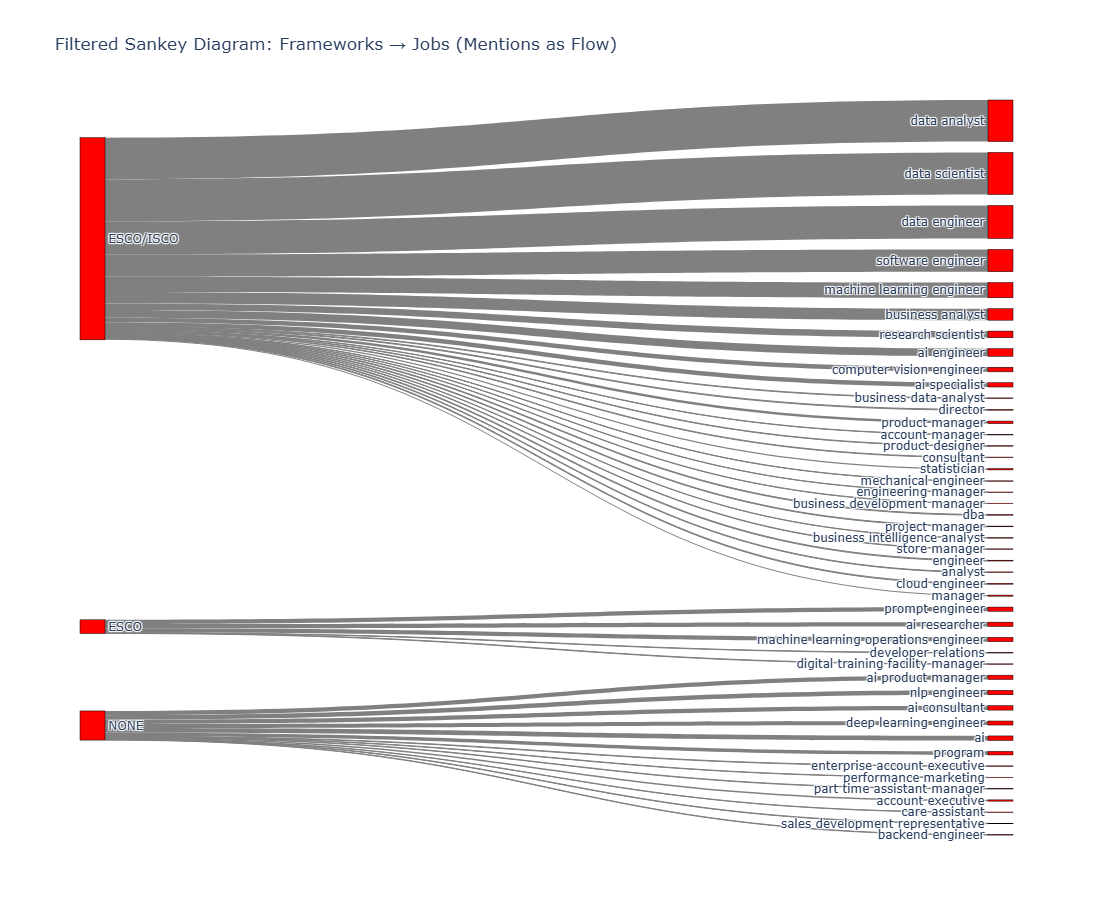

In [6]:
import pandas as pd
import plotly.graph_objects as go

# Load dataset
jobs_df = pd.read_csv("C:\\Users\\Lamees\\Documents\\Lamees Group project\\ONET+framework+llm\\job_title_results_filled.csv")

# filter to reduce clutter 
filtered_df = jobs_df[jobs_df["postings"] > 50]

sources = []
targets = []
values = []

# Collect unique labels for frameworks + jobs
labels = list(set(jobs_df["framework"].unique().tolist() + filtered_df["title_clean"].unique().tolist()))

for _, row in filtered_df.iterrows():
    job = row["title_clean"]
    postings = row["postings"]
    for fw in str(row["framework"]).split(","):
        fw = fw.strip()
        sources.append(labels.index(fw))
        targets.append(labels.index(job))
        values.append(postings)

fig = go.Figure(go.Sankey(
    node=dict(
        pad=30,
        thickness=25,
        line=dict(color="black", width=0.5),
        label=labels,
        color="red"
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color="gray"
    )
))

fig.update_layout(
    title_text="Filtered Sankey Diagram: Frameworks → Jobs (Mentions as Flow)",
    font_size=12,
    width=1100,
    height=900
)
fig.show()
